In [3]:
# pdf 파일 확인
from glob import glob

# glob("../data/*.pdf")

for g in glob("../data/*.pdf"):
    print(g)

../data\2040_seoul_plan.pdf
../data\OneNYC_2050_Strategic_Plan.pdf


In [4]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
# 1단계 : PDF 읽고, 나누고, 나누어진 텍스트 반환 함수

def read_pdf_and_split_text(pdf_path, chunk_size=1000, chunk_overlap=100):  # 인자: (pdf파일, 청크크기, 오버랩크기)
    """
    주어진 PDF 파일을 읽고 텍스트로 분할합니다.
    Args:
        pdf_path (str) : PDF파일의 경로다.
        chunk_size (int, 선택적) : 각 텍스트 청크의 크기. 기본값은 1000이다.
        chunk_overlap (int, 선택적) : 청크 간의 중첩 크기. 기본값은 100이다.
    Return:
        list : 분할된 텍스트 청크를 저장하고 있는 리스트다.
    """
    # 1. PDF 파일 화면에 출력 : PDF 파일 제대로 들어왔는지 확인
    print(f"PDF: {pdf_path}------------------------------------")
    # if 파일 존재 여부 확인 후 아래 코드 작성 필요.
    # 2. PDF 읽기
    pdf_loader = PyPDFLoader(pdf_path)  # 로더 생성 => 읽을 수 있는 것 생성
    data_from_pdf = pdf_loader.load()   # 읽기를 진행, 텍스트 변환

    # 청크 크기와 오버랩 크기 자르기
    text_spliter = RecursiveCharacterTextSplitter(
        chunk_size = chunk_size,    
        chunk_overlap = chunk_overlap
    )
    # 자르기
    splits = text_spliter.split_documents(data_from_pdf)
    print(f"Number of splits : {len(splits)} \n")
    return splits

In [5]:
# 2단계 : 텍스트 -> 위미 벡터 변환, 벡터디비에 저장
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os


##### Vectorstore 설정 #####
# 텍스트를 의미있는 벡터로 변환(임베딩)
embedding = OpenAIEmbeddings(model='text-embedding-3-large')


persist_directory='../chroma_store'


if os.path.exists(persist_directory):
    # 벡터디비가 현재 존재
    print("Loading existing Chroma store")
    vectorstore = Chroma(
        persist_directory=persist_directory,
        embedding_function=embedding
    )
else:
    # 벡터디비가 없다, 생성
    print("Creating new Chroma store")
   
    vectorstore = None # 변수 선언
    for g in glob('../data/*.pdf'): # 두번 반복
        chunks = read_pdf_and_split_text(g) #[Document,,,,,,,] 예 : 291개 -> 3번 저장
        # 100개씩 나눠서 저장
        for i in range(0, len(chunks), 100): # 3번 반복, 100개 저장하는 이유 안정성 때문에
            if vectorstore is None: # 없으면 참
                vectorstore = Chroma.from_documents( # Chroma : 저장(from_document()), 검색(as_retriever())
                    documents=chunks[i:i+100],
                    embedding=embedding,
                    persist_directory=persist_directory
                )
            else:
                vectorstore.add_documents(
                    documents=chunks[i:i+100]
                )


Creating new Chroma store
PDF: ../data\2040_seoul_plan.pdf------------------------------------
Number of splits : 288 

PDF: ../data\OneNYC_2050_Strategic_Plan.pdf------------------------------------
Number of splits : 1022 



In [6]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 5}) # 벡터디비를 검색할 수 있는 객체로 상태 변환


chunks = retriever.invoke("서울 온실가스 저감 계획") # 검색


for chunk in chunks:
    print(chunk.metadata)
    print(chunk.page_content)


{'pdfversion': '1.4', 'total_pages': 205, 'source': '../data\\2040_seoul_plan.pdf', 'author': 'SI', 'page_label': '64', 'creationdate': '2024-12-12T18:16:11+09:00', 'creator': 'Hwp 2020 11.0.0.5178', 'producer': 'Hancom PDF 1.3.0.542', 'moddate': '2024-12-12T18:16:11+09:00', 'page': 63}
56 제2장 미래상과 목표
6. 미래위기를 준비하는, ‘탄소중립 안전도시 구축’
1) 배경
전(全) 지구적인 기후변화에 대응하기 위한 대도시 차원의 대응 필요
Ÿ 서울시 2017년 온실가스 배출량은 46,685천 톤CO2eq로 2005년 배출량에 비해 5.6%(276만 톤
CO2eq) 감소하였으며, 서울의 1인당 온실가스 배출량은 4.7CO2eq로 국가의 13.8톤CO2eq에 비
해 낮은 수준이다. 또한 2014년 기준 서울의 1인당 온실가스 배출량은 4.5CO2eq로 세계 주요 도시
에 비해 낮은 수준을 보인다.7)
[그림 2-26] 세계 주요 도시 1인당 온실가스 배출량
   자료: World Bank, 2014
Ÿ 그럼에도 불구하고, 기후변화 문제는 21세기에 전 지구적으로 가장 위중한 영향을 미칠 것으로 예
상되는바, 탄소중립과 기후위기 대응은 국제·국가·도시의 핵심 정책으로 다루어져야 한다.
Ÿ 파리협정(2015) 이후, 우리나라를 비롯한 미국, 유럽연합 등 세계 136개국이 탄소중립을 선언하였
으며, 서울시를 비롯한 뉴욕, 런던 등과 같은 많은 글로벌 도시에서 탄소중립을 시정의 핵심과제로 
추진 중이다.
Ÿ 우리나라는 2020년 ‘한국판 그린뉴딜’을 발표하며 공식적으로 2050 탄소중립을 선언하였으며 
서울시 역시 2020년 ‘그린뉴딜 추진을 통한 2050 온실가스 감축 전략’을 발표하고 탄소중립 선언에 
따른 부문별 사업을 적극 추진하고 있다

In [8]:
# LangGraph + RAG
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-5.5")
model.invoke("안녕하세요?")

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.5-2026-04-23', 'system_fingerprint': None, 'id': 'chatcmpl-EbHHVf0IxubJZcCBJ9LbK4y5N6xUY', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15c80-49e9-7761-9cbb-058b31720cd3-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [9]:
# 라우터 설정 : 조건부 분기(if)
# ChatPromptTemplate : AI에게 줄 지시문(프롬프트) 양식(폼)을 생성.
from langchain_core.prompts import ChatPromptTemplate
# Literal : 특정 문자열 값들 중 하나만 허용하도록 제한할 때 사용.
from typing import Literal  # 문자열 리터럴 타입을 지원하는 typing 모듈의 클래스
# pydantic : 데이터 형식(포멧) 검증 도구.
from pydantic import BaseModel, Field

# 라우팅: 1. 일상대화, 2. RAG 필요한 경우
# 클래스 선언(Route:  분기, Query: 질문)
# 라우팅 결정을 내릴 때 사용할 데이터 모델(규격)을 정의하는 클래스
# datasource 검증 : 모델이 선택하게 하겠다.
class RouteQuery(BaseModel):
    """사용자 쿼리(질문)에 가장 관련성이 높은 데이터 소스를 라우팅합니다."""
    datasource: Literal["vectorstore", "casual_talk"] = Field(
        ..., # ...은 이 필드가 필수(생략 불가) datasource는 필수
        description="""
        사용자의 질문에 따라 casual_talk 또는 vectorstore로 라우팅합니다.
        - casual_talk : 일상 대화를 위한 데이터 소스. 사용자가 일상적인 질문할 때 사용합니다.
        - vectorstore : 사용자의 질문에 답하기 위해 RAG로 vectorstore 검색이 필요한 경우 사용합니다.
        """
    )

In [13]:
# 모델(model)을 구조화된 출력("vectorstore", "casual_talk")과 함께 사용하기 위한 설정.
structured_llm_router = model.with_structured_output(RouteQuery)

# structured_llm_router 사용하는 시스템 프롬프트
router_system_prompt = """
당신은 사용자의 질문을 vectorstore 또는 casual_talk으로 라우팅하는 전문가입니다.
- vectorstore에는 서울, 뉴욕의 발전계획과 관련된 문서가 포함되어 있다. 이 주제에 대한 질문에서 vectorstore를 사용해라.
사용자의 질문이 일상 대화에 관련된 경우 casual_talk을 사용해라.
"""

In [14]:
route_prompt = ChatPromptTemplate.from_messages([
    ("system", router_system_prompt),   # system 프롬프트 설정
    ("human", "{question}"),
])

# chain
question_router = route_prompt | structured_llm_router

In [17]:
# 2가지 테스트 진행
# 질문 => vectorstore, casual_talk
print(
    question_router.invoke({
        "question":"서울 온실가스 저감 계획은 무엇인가요?"
    })
)

datasource='vectorstore'


In [18]:
print(
    question_router.invoke({
        "question":"잘 지냈니?"
    })
)

datasource='casual_talk'


In [ ]:
# 7단계 : [Document,,,,,,,] 검색된 문서가 사용자의 질문과 실제로 관련이 있는지
# LLM이 'Yes' 또는 'No'로 평가하게 한다
# LLM이 관련 자료만 받아 더 정확하게 답변할 수 있음.(내용과 관련없는 청크는 안 보냄.)

from langchain_core.prompts import PromptTemplate
# pydantic module BaseModel class
# AI(LLM)가 출력할 형식을 고정
class GradeDocuments(BaseModel):
    """검색된 문서가 질문과 관련성 있는지 yes 또는 no로 평가합니다."""


    binary_score: Literal["yes", "no"] = Field(
        description="문서가 질문과 관련이 있는지 여부를 'yes' 또는 'no'로 평가합니다."
    )
# with_structured_output : GradeDocuments 객체를 반환하도록 연결하는 메소드
structured_llm_grader = model.with_structured_output(GradeDocuments)


In [24]:
# 문자열 형식의 텍스트를 모델이 처리할 수 있는 프롬프트 탬플릿 객체 생성
# {document} 부분을 통해 동적으로 데이터 주입
grader_prompt = PromptTemplate.from_template("""
당신은 검색된 문서가 사용자 질문과 관련이 있는지 평가하는 평가자입니다. \n
문서에 사용자 질문과 관련된 키워드 또는 의미가 포함되어 있으면, 해당 문서를 관련성이 있다고 평가하십시오. \n
엄격한 테스트가 필요하지 않습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다. \n
문서가 질문과 관련이 있는지 여부를 나타내기 위해 'yes' 또는 'no'로 이진 점수를 부여하십시오.
                                             
Retrieved document: \n {document} \n\n
User question: {question}
""")


retrieval_grader = grader_prompt | structured_llm_grader
question = "서울시 자율주행 관련 계획"
documents = retriever.invoke(question) # 벡터디비에서 검색 => [Document,,,,,]


for doc in documents:
    print(doc)
    print("="*100)


page_content='확충한다.
- 자율주행 자동차 기반 구축, 서울형 도심항공 교통인프라 확보, 모빌리티 허브 및 3차원 물류체계 
구축 등 도시인프라 확충을 위한 기반 마련 필요
Ÿ 신 교통수단과 기존 대중교통의 원활한 환승체계 구축을 위해 주요 거점에 광역형, 지역형, 근린형 
등 중심지 위계에 따른 유형별 환승체계를 계획한다.' metadata={'source': '../data\\2040_seoul_plan.pdf', 'author': 'SI', 'pdfversion': '1.4', 'page': 114, 'moddate': '2024-12-12T18:16:11+09:00', 'creator': 'Hwp 2020 11.0.0.5178', 'page_label': '115', 'total_pages': 205, 'producer': 'Hancom PDF 1.3.0.542', 'creationdate': '2024-12-12T18:16:11+09:00'}
page_content='54 제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 
교통체계 구축을 준비해야 한다.
미래교통수단 정착을 위한 도시 인프라 확충지원 필요
Ÿ 기존에 없던 새로운 교통은 통상 인프라 구축에 많은 시간이 소요되기 때문에 교통수단이 도입된 이
후에 준비하기보다는 개발단계에서부터 이를 지원하기 위한 교통인프라 구축 구상이 요구되며, 새
로운 도시 인프라 확충에 대한 도시계획적 지원이 필요하다.
2) 추진전략
자율주행 자동차 본격 운영 체계 구축
Ÿ 자율주행은 현재 제일 가시화되고 있는 미래 교통기술로 시장의 주도권을 확보하기 위해 각국의 
노력이 집중되고 있다. 단계적으로 2030년

In [29]:
# yes인 청크만 filtering
filtered_docs = []  # yes인 document들 저장 리스트

# 5번 반복: document가 5개니까.
for idx, doc in enumerate(documents):
    print(f"Document{idx+1}")
    is_relevant = retrieval_grader.invoke({
        "question":question,
        "document":doc.page_content,    # 검색한 내용
    })
    print(is_relevant)  # yes/no
    print(doc.page_content[:200])
    print("="*100)

    if is_relevant.binary_score == "yes":
        filtered_docs.append(doc)

print(f"Filtered Documents : {len(filtered_docs)}")

Document1
binary_score='yes'
확충한다.
- 자율주행 자동차 기반 구축, 서울형 도심항공 교통인프라 확보, 모빌리티 허브 및 3차원 물류체계 
구축 등 도시인프라 확충을 위한 기반 마련 필요
Ÿ 신 교통수단과 기존 대중교통의 원활한 환승체계 구축을 위해 주요 거점에 광역형, 지역형, 근린형 
등 중심지 위계에 따른 유형별 환승체계를 계획한다.
Document2
binary_score='yes'
54 제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 
Document3
binary_score='no'
서울도시기본계획에서 새롭게 제시하는 공간구조인 보행일상권을 실현하기 위한 계획으로 역할을 
전환한다.
12) 맹다미 외, 2022, 미래 여건변화에 대응하는 도시계획체계 개편방안 연구, 서울연구원
Document4
binary_score='yes'
36 제2장 미래상과 목표
6) 미래교통수단의 등장과 첨단 인프라 요구 증대
자율주행, UAM 등 미래 교통에 공간적 대응방안 마련 필요
Ÿ 자율주행차량, 전동킥보드 등 교통 기술의 발전에 따라 
새로운 교통환경이 조성되고 있음에도 불구하고, 이에 대한 
정착 가이드라인이 없어, 위험한 교통 사고가 유발되고 
있다.
- 최근 3년간 서울시에서 발생한 전동킥
Document5
binary_score='yes'
Ÿ 미래교통수단 도입에 따른 3차원 교통시스템 구축
Ÿ 기후위기에 선제적 대응, 신종 도시재난에 사전 예방으로 쾌적하고 안전한 환경 구축
서울형 용도지역제(Beyond Zoning)를 실현하기 위한 단계별 전략
Ÿ 단기: 현행 규제하에서 유연한 용도지역제 운영을 위한 용도지역 변경 간 장벽 해소
Ÿ 

In [30]:
### Generate
# PromptTemplate을 사용하여 RAG를 위한 프롬프트를 생성합니다.
# 1. LLM 에게 부여할 역할과 답변 형식을 정의하는 지시문을 작성
rag_generate_system = """
너는 사용자의 질문에 대해 주어진 context에 기반하여 답변하는 도시 계획 전문가이다.
주어진 context는 vectorstore에서 검색된 결과이다.
주어진 context를 기반으로 사용자의 question에 대해 답변하라.


=================================
question: {question}
context: {context}
"""


# PromptTemplate을 생성하여 question과 context를 포맷팅
rag_prompt = PromptTemplate(
    input_variables=["question", "context"],
    template=rag_generate_system
)


# rag chain
rag_chain = rag_prompt | model


# 사용자 질문과 검색된 문서를 입력으로 사용하여 RAG를 실행
question = "서울시 자율주행 관련 계획"


rag_chain.invoke({"question": question, "context": filtered_docs})


AIMessage(content='서울시의 자율주행 관련 계획은 「2040 서울도시기본계획」에서 ‘미래교통 인프라 구축’ 전략의 핵심 과제로 제시되어 있습니다. 주요 내용은 다음과 같습니다.\n\n### 1. 자율주행 자동차 본격 운영 체계 구축\n서울시는 자율주행을 가장 가시화된 미래 교통기술로 보고, 단계적으로 운행 기반을 마련할 계획입니다.\n\n- **2030년까지**: 간선도로급 이상 도로에서 자율주행차가 운영될 수 있는 **도로 인프라 환경 조성**\n- **2040년까지**: **서울 전역에서 자율주행차 운행이 가능한 환경 구축**\n- **목표**: 2040년까지 자율주행차의 **수송 분담률 10% 달성**\n\n즉, 초기에는 주요 간선도로를 중심으로 자율주행 기반을 구축하고, 장기적으로는 서울 전역으로 확대하는 단계적 접근을 취하고 있습니다.\n\n### 2. 기존 대중교통과의 연계\n자율주행차를 별도의 교통수단으로만 보는 것이 아니라, 기존 대중교통과 원활히 연결하는 방향으로 계획하고 있습니다.\n\n- 신교통수단과 기존 대중교통 간 **환승체계 구축**\n- 주요 거점에 중심지 위계에 따라  \n  - 광역형  \n  - 지역형  \n  - 근린형  \n  환승체계를 계획\n\n이를 통해 자율주행차가 지하철, 버스 등 기존 대중교통을 보완하는 수단으로 활용될 수 있도록 하는 구상입니다.\n\n### 3. 모빌리티 허브와 연계\n서울시는 자율주행을 포함한 미래교통수단을 수용하기 위해 **모빌리티 허브**를 서울 전역에 구축할 계획입니다.\n\n모빌리티 허브는 단순한 환승시설이 아니라 다음 기능을 복합적으로 제공하는 지역 거점입니다.\n\n- 미래교통과 기존 교통의 연결\n- 공공서비스 제공\n- 물류 기능\n- 상업 기능\n- 지역 생활거점 기능\n\n특히 도심 및 광역거점에는 서울 내부와 외부를 연결하는 미래교통 연계시설을 도입할 계획입니다.\n\n### 4. 통합적 교통수단 정착 가이드라인 필요\n자율주행차, 전동킥보드, UAM 등 새로운

In [ ]:
# 그래프 설계 : 노드, 엣지, 상태(메시지)
# 1. 상태 클래스: 메시지(질문,답변,검색된 문서) 저장
# 질문, 답변, 검색된 문서 클래스 선언
from typing import List #[], list()는 function. List 타입 import
from typing_extensions import TypedDict
from langchain_core.documents import Document
from langchain_core.messages import AIMessage

# 상태를 저장하는 클래스 선언 시 반드시 TypedDict 상속해야 한다.
class GraphState(TypedDict):    # invoke마다 새로 시작. 상태는 invoke할 때마다 저장. state는 대화를 저장하는 게 아님.
    question:str    # 사용자로부터 입력받은 최초의 질문을 문자열 형태로 저장
    generation: AIMessage  # LLM이 생성한 답변. 마지막 꺼만 저장.     # Annotate했던 건 질/답 하나로 합쳐주기 위함. 
    documents:List[Document]     # 검색된 청크 저장
    # 돌아오는 변수의 타입에 맞게 타입 힌트를 둬야 함.

In [34]:
# 지능형(AI) 라우팅 노드 => 결과적으로 함수
# 사용자의 질문을 분석하여 어떤 노드(검색, 일상대화)로 이동할지 결정하는 함수(노드)
# vectorstore / casual_talk 반환 노드
def route_question(state:GraphState):   # 노드는 state 받아야 함. 상태를 받아야 함.
                                        # state 안 받는 함수는 일반함수.
    """
    사용자의 질문을 vectorstore 또는 casual_talk로 라우팅한다.
    Args:
        state (dict) : 현재 graph의 상태를 저장한다. 라우팅 전
    return:
        state (dict) : 라우팅 후의 데이터소스와 사용자 질문을 포함하는 새로운 state를 반환.
    """
    print("----------Route--------------")
    question=state["question"]  # 질문 추출
    route = question_router.invoke({"question":question})   # LLM => vectorstore / casual_talk
    print(f"-- Routing to {route.datasource}")
    return route.datasource    

In [35]:
# vectorstore일 때 검색하는 노드
# route_question node 나온 결과가 vectorstore인 경우 처리하는 노드
def retrieve(state:GraphState):
    """
    vectorstore에서 질문에 대한 문서를 검색한다.
    Args:
        state (dict) : 현재 graph state
    return:
        state (dict) : 검색된 문서와 사용자 질문을 포함하는 새로운 graphstate
    """
    print("----- Retrieve --------")
    question = state["question"]    # 질문 추출 => 벡터db에 검색.
    # 검색 => Documents 반환된다.
    documents=retriever.invoke(question)
    # 노드의 return은 상태에 저장된다.
    return {"documents":documents, "question":question}

In [37]:
# 검색 결과 검증 : yes/no
# 14 단계 : 검색한 문서에 평가, yes/no
def grade_documents(state):
    """
    검색된 문서를 평가하여 질문과 관련성이 있는지 확인합니다.


    Args:
        state (dict): 현재 graph state


    return:
        state (dict): 관련성이 있는 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GRADE------')
    question = state['question']
    documents = state['documents']
    filtered_docs = []


    for i, doc in enumerate(documents):
        is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
        if is_relevant.binary_score == "yes":
            filtered_docs.append(doc)
    return {"documents": filtered_docs, "question": question}  # GraphState 저장


In [38]:
# 답변 생성 노드
def generate(state:GraphState):
    """
    LLM을 사용하여 문서와 사용자 질문에 대한 답변을 생성합니다.


    Args:
        state (dict): 현재 graph state


    return:
        state (dict): LLM 생성 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GENERATE------')
    question = state['question']
    documents = state['documents']
    generation = rag_chain.invoke({"question": question, "context": documents})
    return {
        "documents": documents,
        "question": question,
        "generation": generation
    }


In [39]:
# 일상 대화 처리 노드
def casual_talk(state):
    """
    일상 대화를 위한 답변을 생성합니다.


    Args:
        state (dict): 현재 graph state


    return:
        state (dict): 일상 대화 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------CASUAL TALK------')
    question = state['question']
    generation = model.invoke(question)
    return {
        "question": question,
        "generation": generation
    }


In [ ]:
from langgraph.graph import START, StateGraph, END


# 그래프를 관리하는 객체를 생성
workflow = StateGraph(GraphState)
# 노드를 정의
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("casual_talk", casual_talk)
 

In [ ]:
# 그래프 엣지 연결 및 컴파일

In [42]:
# 그래프 엣지 연결 및 컴파일
workflow.add_conditional_edges(
    START,
    route_question,
    {
        "vectorstore": "retrieve",
        "casual_talk": "casual_talk"
    }
)
workflow.add_edge("casual_talk", END)
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("grade_documents", "generate")
workflow.add_edge("generate", END)


app = workflow.compile() # workflow를 컴파일


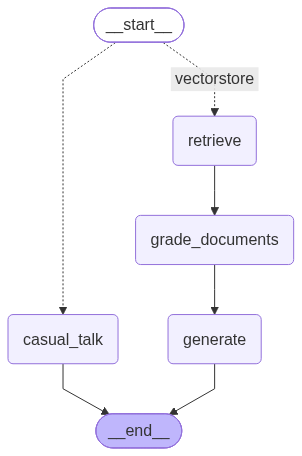

In [44]:
from IPython.display import Image, display


try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    #  실패 시 통과
    pass


In [47]:
inputs={
    "question":"서울시 자율주행 계획"
}

app.invoke(inputs)

----------Route--------------
-- Routing to vectorstore
----- Retrieve --------
------GRADE------
------GENERATE------


{'question': '서울시 자율주행 계획',
 'generation': AIMessage(content='서울시의 자율주행 계획은 「2040 서울도시기본계획」에서 미래교통 인프라 구축 전략의 핵심 과제로 제시되어 있습니다.\n\n주요 내용은 다음과 같습니다.\n\n1. **자율주행 자동차 운영 기반 구축**\n   - 자율주행을 가장 가시화된 미래 교통기술로 보고, 서울시 차원에서 본격적인 운영 체계를 마련하려는 계획입니다.\n   - 단순한 차량 도입이 아니라, 도로·교통 인프라와 도시공간 구조를 함께 정비하는 방향입니다.\n\n2. **2030년까지 간선도로급 이상 도로 중심 인프라 조성**\n   - 단계적으로 2030년까지 서울의 간선도로급 이상 도로에서 자율주행차가 운행할 수 있는 도로 인프라 환경을 조성하는 것이 목표입니다.\n   - 이는 자율주행차가 안전하게 운행할 수 있도록 도로, 신호, 통신, 교통관리 체계 등을 정비하는 방향으로 이해할 수 있습니다.\n\n3. **2040년까지 서울 전역 자율주행 운행 환경 구축**\n   - 장기적으로는 2040년까지 서울 전역에서 자율주행차량이 운행 가능한 환경을 구축하는 것을 목표로 합니다.\n   - 계획상 자율주행차의 **수송 분담률 10% 달성**도 제시되어 있습니다.\n\n4. **기존 대중교통 및 신교통수단과의 연계**\n   - 자율주행차는 UAM, 모빌리티 허브, 3차원 물류체계 등 다른 미래교통수단과 함께 통합적으로 계획됩니다.\n   - 주요 거점에는 광역형·지역형·근린형 환승체계를 마련하여 기존 대중교통과 신교통수단 간 환승이 원활하도록 할 계획입니다.\n\n5. **안전하고 통합적인 교통 가이드라인 필요**\n   - 자율주행차, 전동킥보드, UAM 등 새로운 교통수단이 등장하면서 기존 교통수단과의 충돌 가능성도 커지고 있습니다.\n   - 이에 따라 서울시는 신규 교통수단이 안전하게 정착할 수 있도록 통합적인 교통수단 정착 가이드라인과 도시계획적 대응이 필요하다고 보고 있습니

In [49]:
inputs={
    "question":"안녕. 나는 yun이야"
}

app.invoke(inputs)

----------Route--------------
-- Routing to casual_talk
------CASUAL TALK------


{'question': '안녕. 나는 yun이야',
 'generation': AIMessage(content='안녕, yun! 만나서 반가워 😊  \n무엇을 도와줄까?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 13, 'total_tokens': 36, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.5-2026-04-23', 'system_fingerprint': None, 'id': 'chatcmpl-EbL6IHwM5J2O3Cepzd9Ue70CbfGSu', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15d60-4ac8-7070-a4c4-256d540f56dd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 23, 'total_tokens': 36, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 

In [50]:
inputs={
    "question":"내 이름 뭐라고?"
}

app.invoke(inputs)

----------Route--------------
-- Routing to casual_talk
------CASUAL TALK------


{'question': '내 이름 뭐라고?',
 'generation': AIMessage(content='아직 제게 이름을 알려주지 않으셨어요.  \n알려주시면 기억하고 그렇게 불러드릴게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 11, 'total_tokens': 78, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 28, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.5-2026-04-23', 'system_fingerprint': None, 'id': 'chatcmpl-EbL6RbKm5CTMsND3iNtEFbmajJuvU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15d60-6bdf-7042-8027-620895303e13-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 67, 'total_tokens': 78, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_detail

In [52]:
#  20 단계
inputs = {
    "question": "서울시의 자율주행 차량 관련 계획은 무엇이 있나요?"
}


for msg, meta in app.stream(inputs, stream_mode='messages'):
    print(msg.content, end='')


----------Route--------------
{"datasource":"vectorstore"}-- Routing to vectorstore
----- Retrieve --------


c:\big21\agentic_ai\venv\lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=RouteQuery(datasource='vectorstore'), input_type=RouteQuery])
  return self.__pydantic_serializer__.to_python(


------GRADE------
{"binary_score":"yes"}

c:\big21\agentic_ai\venv\lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='yes'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


{"binary_score":"yes"}

...

{"binary_score":"yes"}

c:\big21\agentic_ai\venv\lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='yes'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


{"binary_score":"no"}------GENERATE------


c:\big21\agentic_ai\venv\lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='no'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


서울시의 자율주행 차량 관련 계획은 「2040 서울도시기본계획」의 ‘미래교통 인프라 구축’ 전략에 포함되어 있습니다. 핵심은 자율주행차가 실제로 운행될 수 있는 도시 인프라와 운영 환경을 단계적으로 마련하는 것입니다.

주요 내용은 다음과 같습니다.

1. **자율주행 자동차 본격 운영 체계 구축**
   - 서울시는 자율주행을 가장 가시화된 미래 교통기술로 보고, 이에 대응하기 위한 운영 체계를 구축하려고 합니다.
   - 단순한 시범사업을 넘어 도로 인프라, 교통관리, 도시계획적 지원을 포함한 기반을 마련하는 방향입니다.

2. **2030년까지 간선도로급 이상 도로에 자율주행 인프라 조성**
   - 단계적으로 **2030년까지 간선도로급 이상 도로에서 자율주행차가 운행할 수 있는 도로 인프라 환경**을 조성하는 것이 목표입니다.
   - 이는 주요 도로부터 자율주행 운행 여건을 갖추겠다는 의미입니다.

3. **2040년까지 서울 전역 자율주행 운행 환경 구축**
   - 장기적으로는 **2040년까지 서울 전역에서 자율주행차량이 운행 가능한 환경**을 구축하는 것을 목표로 합니다.
   - 이를 통해 서울 전역에서 자율주행 교통체계가 작동할 수 있도록 도시 인프라를 정비하려는 계획입니다.

4. **자율주행차 수송분담률 10% 달성 목표**
   - 2040년까지 자율주행차량의 **수송 분담률 10% 달성**을 목표로 제시하고 있습니다.
   - 이는 전체 도시교통에서 자율주행차가 일정 비중을 담당하도록 하겠다는 계획입니다.

5. **기존 대중교통 및 신교통수단과의 연계**
   - 자율주행차뿐 아니라 UAM, 모빌리티 허브 등 다른 미래교통수단과 연계한 교통체계도 함께 구상하고 있습니다.
   - 주요 거점에는 광역형, 지역형, 근린형 등 중심지 위계에 따른 환승체계를 계획하여 기존 대중교통과 신교통수단이 원활히 연결되도록 할 예정입니다.

정리하면, 서울시는 **2030년까지 주요 간선도로 중심의 자율주행 인프라를 구축하고, 2040년까지 서울 